<a href="https://colab.research.google.com/github/Dharnipatel21/dissipative-opinf-regional-weather/blob/main/tamilnadu_reduced_order_modeling_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Structure-aware reduced-order modeling of regional atmospheric dynamics (Tamil Nadu, ERA5-Land)

**Research question.** Can a *small* model (10 numbers instead of ~6500) describe and forecast the hourly near-surface atmosphere over Tamil Nadu, and does building physical structure into that small model (an energy-preserving nonlinearity) make it more stable than an unconstrained one?

**Methods (all non-intrusive: they use only data, not the governing equations)**

| step | method | why |
|---|---|---|
| A | **POD** (proper orthogonal decomposition) | how many modes describe the system? |
| B | **Quadratic manifold** vs linear subspace | does curvature help to describe the fields with the same number of modes? |
| C | **Operator inference** (linear, quadratic) | learn the reduced equations `dz/dt = c + A z + H(z⊗z) + B u` from data |
| D | **Energy-preserving operator inference** | force the nonlinear term to satisfy `zᵀ H(z⊗z) = 0` (it can move energy between modes but not create it) |
| D2 | **Dissipative linear part** | write `A = J − D` with `J` skew-symmetric and `D` positive definite, so the *unforced* model can never gain energy; combined with D it gives a bounded model |
| E | **Dynamical-systems analysis** | error growth with lead time, stability of 30-day free runs, eigenvalues of the learned linear operator |

**Data.** ERA5-Land hourly, 2 m temperature, 2 m dew point, 10 m wind (u, v), surface pressure, Tamil Nadu land cells, 2020–2024. Training = 2020–2022, validation = 2023, test = 2024 (whole calendar years, no leakage). Rain is left out on purpose: it is intermittent and not smooth, which suits neither POD nor polynomial models.

**Honest scope.** The atmosphere near the surface is *forced* (the sun) and *dissipative* (friction), so it is **not** a Hamiltonian system. Two structural constraints are tested separately and together: an energy-preserving *nonlinear term* (as in energy-preserving operator inference for quadratic systems) and a *dissipative linear part*. The forcing term is always free. The experiment tests whether that structure helps stability and accuracy, it does not claim the atmosphere conserves energy.

**Data actually used.** Only the hourly files that exist are used; there is no re-download. 2021 is absent and parts of 2020 and 2024 are missing, so training = whatever hours exist in 2020 and 2022, validation = 2023, test = the hours that exist in 2024. Samples never span a gap. The month-by-month coverage table printed by Cell 5 shows exactly which months are present; because missing months can bias the seasons the models see, treat the results as a study on this data subset, not as a full five-year study.

Run the cells in order. Cells 1–5 load and prepare the data, 6–8 are the POD and manifold study, 9–13 are operator inference and its analysis, 14 saves everything.

### Cell 1 — setup, Drive, folders

In [15]:
# Cell 1 — setup, Drive, folders
%pip install -q xarray netCDF4 geopandas regionmask scikit-learn
import os, glob, json, zipfile, subprocess, time, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from sklearn.utils.extmath import randomized_svd
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE = "/content/drive/MyDrive/iitp_project"                   # same project folder as the earlier notebooks
OUT = f"{BASE}/rom_research"                                   # everything from this notebook is saved here
FIG, TAB, MOD = f"{OUT}/figures", f"{OUT}/tables", f"{OUT}/models"
for d in (OUT, FIG, TAB, MOD):
    os.makedirs(d, exist_ok=True)
HOURLY_DIRS = [f"{BASE}/raw", "/content/drive/MyDrive/iitm"]    # where the ERA5-Land hourly files (or zips) are
SHP_DIR = "/content/india_shp"
SCRATCH = "/content/hourly_unzipped"

SPLITS = {"train": ("2020-01-01", "2022-12-31"), "val": ("2023-01-01", "2023-12-31"), "test": ("2024-01-01", "2024-12-31")}
VARS = ["t2m", "d2m", "u10", "v10", "sp"]                       # the state: these five fields on every Tamil Nadu land cell
UNITS = {"t2m": "°C", "d2m": "°C", "u10": "m/s", "v10": "m/s", "sp": "hPa"}
R_MODES = 10                                                    # size of the reduced model
SUB = 3                                                         # use every 3rd training hour for the SVD (speed)
print("project folder:", BASE, "| exists:", os.path.isdir(BASE))
print("results go to:", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/iitp_project | exists: True
results go to: /content/drive/MyDrive/iitp_project/rom_research


### Cell 2 — Tamil Nadu boundary

In [16]:
# Cell 2 — Tamil Nadu boundary
import geopandas as gpd, regionmask
if not glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True):
    subprocess.run(["git", "clone", "-q", "https://github.com/AnujTiwari/India-State-and-Country-Shapefile-Updated-Jan-2020", SHP_DIR])
shps = sorted(glob.glob(f"{SHP_DIR}/**/*.shp", recursive=True))
state_shp = [s for s in shps if "state" in os.path.basename(s).lower()]
assert state_shp, f"state boundary shapefile not found in {SHP_DIR}"
ST = gpd.read_file(state_shp[0]); ST = ST.set_crs(4326) if ST.crs is None else ST.to_crs(4326)
rows = set()
for col in ST.columns:
    if ST[col].dtype == object or pd.api.types.is_string_dtype(ST[col]):
        rows |= {i for i, v in ST[col].astype(str).items() if "tamil" in v.lower()}
TN_POLY = ST.loc[sorted(rows)].dissolve() if rows else None
print("Tamil Nadu polygon found:", TN_POLY is not None)

def tn_mask(lat, lon):
    if TN_POLY is None:
        return np.ones((len(lat), len(lon)), bool)
    return regionmask.from_geopandas(TN_POLY).mask(np.asarray(lon), np.asarray(lat)).notnull().values

Tamil Nadu polygon found: True


### Cell 3 — find and load the hourly ERA5-Land files

In [17]:
# Cell 3 — find and load the hourly ERA5-Land files
def tcoord(d):
    return "valid_time" if "valid_time" in d.coords else "time"

def find_hourly_files():
    os.makedirs(SCRATCH, exist_ok=True)
    for root in HOURLY_DIRS:
        for z in glob.glob(f"{root}/**/*.zip", recursive=True):
            dest = os.path.join(SCRATCH, os.path.splitext(os.path.basename(z))[0])
            if os.path.isdir(dest):
                continue
            with zipfile.ZipFile(z) as zf:
                if any("daily" in n.lower() for n in zf.namelist()):
                    continue
                zf.extractall(dest)
    paths = sorted(set(p for r in HOURLY_DIRS + [SCRATCH] for p in glob.glob(f"{r}/**/*.nc", recursive=True)))
    paths = [p for p in paths if "/processed/" not in p and "/rom_research/" not in p and "daily" not in os.path.basename(p).lower()]
    rows = []
    for p in paths:
        try:
            with xr.open_dataset(p) as d:
                t = tcoord(d)
                if set(VARS) <= set(d.data_vars) and d.sizes[t] >= 24:
                    rows.append(dict(path=p, steps=d.sizes[t], start=pd.Timestamp(d[t].values[0]),
                                     grid=f"{d.sizes['latitude']}x{d.sizes['longitude']} lat {float(d.latitude.min()):.1f}-{float(d.latitude.max()):.1f} lon {float(d.longitude.min()):.1f}-{float(d.longitude.max()):.1f}"))
        except Exception as e:
            print("unreadable, skipped:", os.path.basename(p), str(e)[:60])
    scan = pd.DataFrame(rows)
    assert len(scan), "no hourly ERA5-Land files found - add their folder to HOURLY_DIRS"
    g = scan.groupby("grid")["steps"].sum(); print(g.to_string()); best = g.idxmax()
    print(f"using grid '{best}'; skipped {int((scan.grid != best).sum())} files with another grid")
    return scan[scan.grid == best].sort_values("start").path.tolist()

def build_cube():
    files = find_hourly_files()
    times = pd.date_range("2020-01-01 00:00", "2024-12-31 23:00", freq="h")
    with xr.open_dataset(files[0]) as d0:
        lat, lon = d0.latitude.values.astype("float64"), d0.longitude.values.astype("float64")
    cube = np.full((len(times), len(VARS), len(lat), len(lon)), np.nan, np.float32)
    for f in files:                                           # filled by timestamp, so duplicate files just overwrite identical values
        with xr.open_dataset(f) as d:
            tn = tcoord(d)
            assert np.allclose(d.latitude.values, lat) and np.allclose(d.longitude.values, lon), f"grid differs: {f}"
            ix = times.get_indexer(pd.DatetimeIndex(d[tn].values)); ok = ix >= 0
            for c, v in enumerate(VARS):
                cube[ix[ok], c] = d[v].transpose(tn, "latitude", "longitude").values[ok]
    cube[:, VARS.index("t2m")] -= 273.15; cube[:, VARS.index("d2m")] -= 273.15; cube[:, VARS.index("sp")] /= 100.0
    has = np.isfinite(cube[:, 0]).any(axis=(1, 2))            # hours that really have data
    cov = pd.DataFrame({"hours_with_data": pd.Series(has, index=times).groupby(times.year).sum(),
                        "hours_expected": pd.Series(has, index=times).groupby(times.year).size()})
    print(cov.to_string())
    assert has.sum() > 0, "no hour has any temperature data - check the files in the table above"
    land = np.isfinite(cube[:, 0][has]).mean(axis=0) > 0.99
    assert land.sum() > 0, "no land cells found - the hourly files are probably mostly NaN"
    cells = np.argwhere(land)[:: max(1, int(land.sum()) // 8)]
    valid_t = has & np.all([np.isfinite(cube[:, :, i, j]).all(axis=1) for i, j in cells], axis=0)
    print(f"cube {cube.shape} = {cube.nbytes/1e9:.2f} GB | land cells {int(land.sum())} of {land.size} | usable hours {int(valid_t.sum())} of {len(times)}")
    return dict(data=cube, times=times, lat=lat, lon=lon, land=land, valid_t=valid_t)

### Cell 4 — build the cube (1-3 minutes)

In [18]:
# Cell 4 — build the cube (1-3 minutes)
C = build_cube()

grid
56x46 lat 8.0-13.5 lon 76.0-80.5    46080
using grid '56x46 lat 8.0-13.5 lon 76.0-80.5'; skipped 0 files with another grid
      hours_with_data  hours_expected
2020             7320            8784
2021                0            8760
2022             8688            8760
2023             8760            8760
2024             7368            8784
cube (43848, 5, 56, 46) = 2.26 GB | land cells 1861 of 2576 | usable hours 32136 of 43848


### Cell 5 — splits, standardisation, snapshot matrices, calendar inputs

In [19]:
# Cell 5 — splits, standardisation, snapshot matrices, calendar inputs
def split_times(C, split):                                     # hour indices of a split that have data
    t = C["times"]; lo = t.searchsorted(pd.Timestamp(SPLITS[split][0])); hi = t.searchsorted(pd.Timestamp(SPLITS[split][1]) + pd.Timedelta(days=1))
    return np.arange(lo, hi)[C["valid_t"][lo:hi]]

def standardise(C):                                            # statistics from the TRAIN years only; done in place; sea/missing -> 0
    sub = split_times(C, "train")[::5]; mu, sd = np.zeros(len(VARS)), np.ones(len(VARS))
    for c in range(len(VARS)):
        x = C["data"][sub, c][:, C["land"]].astype(np.float64); mu[c], sd[c] = x.mean(), max(x.std(), 1e-6)
    for c in range(len(VARS)):
        C["data"][:, c] = np.nan_to_num((C["data"][:, c] - mu[c]) / sd[c])
    C["mu"], C["sd"] = mu, sd
standardise(C)
print({v: (round(float(m), 2), round(float(s), 2)) for v, m, s in zip(VARS, C["mu"], C["sd"])}, "(train mean, std)")

MASK = C["land"] & tn_mask(C["lat"], C["lon"]); NC = int(MASK.sum()); NSTATE = NC * len(VARS)
print(f"Tamil Nadu land cells: {NC} | state vector length: {NSTATE} | reduced model size: {R_MODES}")

def snapshots(C, ts, chunk=2000):                              # (state, hours); rows are blocks of NC cells per variable
    out = np.empty((NSTATE, len(ts)), np.float32)
    for i in range(0, len(ts), chunk):
        X = C["data"][ts[i:i + chunk]][:, :, MASK]; out[:, i:i + len(X)] = X.reshape(len(X), -1).T
    return out

def calendar(t):                                               # known forcing: hour of day and day of year, sin/cos
    t = pd.DatetimeIndex(t); hr = t.hour.values + t.minute.values / 60.0; doy = t.dayofyear.values
    return np.stack([np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24), np.sin(2 * np.pi * doy / 366), np.cos(2 * np.pi * doy / 366)], 1)

TR, VA, TE = split_times(C, "train"), split_times(C, "val"), split_times(C, "test")
print("usable hours  train / val / test:", len(TR), len(VA), len(TE))
cov_m = pd.Series(C["valid_t"], index=C["times"])
print("fraction of hours with data, by year (rows) and month (columns):")
print(cov_m.groupby([cov_m.index.year, cov_m.index.month]).mean().unstack().round(2).to_string())
assert len(TR) > 1000 and len(VA) > 500 and len(TE) > 500, "a split is missing most of its data - check the coverage table printed by Cell 4"
Qtr = snapshots(C, TR); print(f"training snapshot matrix {Qtr.shape} = {Qtr.nbytes/1e9:.2f} GB")

{'t2m': (25.71, 4.27), 'd2m': (19.85, 3.54), 'u10': (0.23, 2.1), 'v10': (-0.02, 1.54), 'sp': (967.21, 37.69)} (train mean, std)
Tamil Nadu land cells: 1065 | state vector length: 5325 | reduced model size: 10
usable hours  train / val / test: 16008 8760 7368
fraction of hours with data, by year (rows) and month (columns):
       1    2    3    4    5    6    7    8    9    10   11   12
2020  1.0  1.0  1.0  1.0  1.0  1.0  1.0  0.0  0.0  1.0  1.0  1.0
2021  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
2022  0.9  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0
2023  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0
2024  1.0  0.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  0.0  1.0
training snapshot matrix (5325, 16008) = 0.34 GB


### Cell 6 — POD and quadratic-manifold tools

In [20]:
# Cell 6 — POD and quadratic-manifold tools
def quad_features(Z):                                          # all products z_i z_j (i <= j)
    iu = np.triu_indices(Z.shape[1]); return Z[:, iu[0]] * Z[:, iu[1]]

class POD:
    def fit(self, Q, rmax=60, sub=SUB):
        self.mean = Q.mean(1, keepdims=True).astype(np.float64)
        X = Q[:, ::sub].astype(np.float64) - self.mean; total = float((X ** 2).sum())
        U, S, _ = randomized_svd(X, n_components=rmax, n_iter=4, random_state=0)
        self.V, self.S, self.energy = U, S, np.cumsum(S ** 2) / total; return self
    def project(self, Q, r): return (self.V[:, :r].T @ (Q - self.mean)).T            # (hours, r)
    def lift(self, Z):       return self.V[:, :Z.shape[1]] @ Z.T + self.mean          # (state, hours)

class QuadManifold:
    # q ~ mean + V z + W (z x z): W is fitted to what a straight (linear) subspace misses
    def fit(self, pod, Q, r, lam=1e-3, sub=SUB):
        self.pod, self.r = pod, r; Qs = Q[:, ::sub].astype(np.float64); Z = pod.project(Qs, r); self.zs = Z.std(0) + 1e-12
        E = (Qs - pod.mean) - pod.V[:, :r] @ Z.T; F = quad_features(Z / self.zs)
        self.W = np.linalg.solve(F.T @ F + lam * len(F) * np.eye(F.shape[1]), F.T @ E.T).T; return self
    def lift(self, Z): return self.pod.V[:, :Z.shape[1]] @ Z.T + self.pod.mean + self.W @ quad_features(Z / self.zs).T

## A. How many modes describe Tamil Nadu?
POD finds the directions in state space that capture the most variance. If a few modes capture almost everything, a very small model is possible. For hourly near-surface fields the **daily cycle** is expected to dominate the first modes, which is itself a result worth stating.

### Cell 7 — POD energy decay

,modes,energy_captured
0,1,0.4259
1,2,0.6801
2,3,0.7891
3,5,0.8756
4,10,0.9210
5,20,0.9534
6,40,0.9743
7,60,0.9834


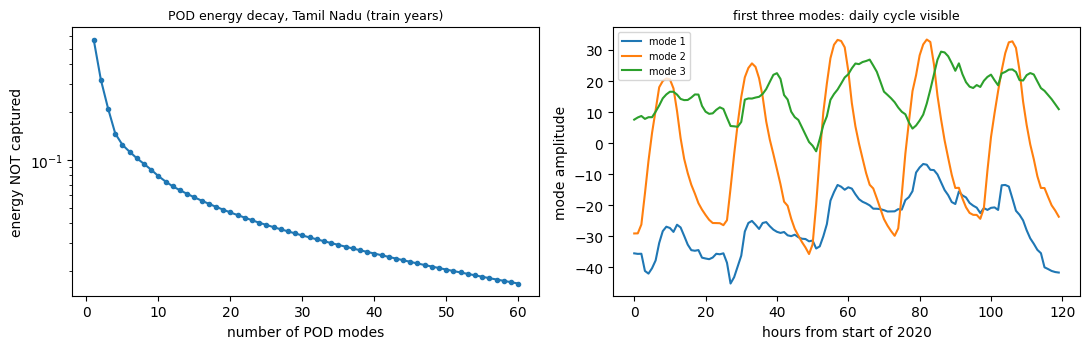

In [21]:
# Cell 7 — POD energy decay
pod = POD().fit(Qtr, rmax=60)
rs = [1, 2, 3, 5, 10, 20, 40, 60]
etab = pd.DataFrame({"modes": rs, "energy_captured": [pod.energy[r - 1] for r in rs]}).round(4)
etab.to_csv(f"{TAB}/A_pod_energy.csv", index=False); display(etab)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].semilogy(np.arange(1, 61), 1 - pod.energy, marker=".")
axs[0].set_xlabel("number of POD modes"); axs[0].set_ylabel("energy NOT captured"); axs[0].set_title("POD energy decay, Tamil Nadu (train years)", fontsize=9)
for k in range(3):                                             # time evolution of the first 3 modes over 5 days
    z = pod.project(snapshots(C, TR[:120]), 3)[:, k]; axs[1].plot(np.arange(120), z, label=f"mode {k+1}")
axs[1].set_xlabel("hours from start of 2020"); axs[1].set_ylabel("mode amplitude"); axs[1].legend(fontsize=7); axs[1].set_title("first three modes: daily cycle visible", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/A_pod_energy.png", dpi=200); plt.show()

## B. Linear subspace or curved (quadratic) manifold?
With the same number of modes, a quadratic manifold adds a curved correction. A positive `improvement` means the data lies on a curved surface that a flat subspace needs more modes to describe.

### Cell 8 — quadratic manifold vs linear POD

In [22]:
# Cell 8 — quadratic manifold vs linear POD
Qte_s = snapshots(C, TE[::4]); rows = []
for r in [3, 5, 10, 20, 40]:
    Z = pod.project(Qte_s, r); lin = float(np.sqrt(np.mean((pod.lift(Z) - Qte_s) ** 2)))
    qm = QuadManifold().fit(pod, Qtr, r); q = float(np.sqrt(np.mean((qm.lift(Z) - Qte_s) ** 2)))
    rows.append(dict(modes=r, linear_RMSE=lin, quadratic_manifold_RMSE=q, improvement=1 - q / lin))
qtab = pd.DataFrame(rows).round(4); qtab.to_csv(f"{TAB}/B_quadratic_manifold.csv", index=False); display(qtab)
print("RMSE is in standardised units on the test year.")

,modes,linear_RMSE,quadratic_manifold_RMSE,improvement
0,3,0.3706,0.3566,0.0376
1,5,0.2906,0.2738,0.0581
2,10,0.2306,0.2142,0.0712
3,20,0.1816,0.1679,0.0755
4,40,0.1366,0.1361,0.0037


RMSE is in standardised units on the test year.


## C–D. Operator inference: learn the small model's equations from data
In POD coordinates `z` (R_MODES numbers) the model is `dz/dt = c + A z + H (z⊗z) + B u(t)`, where `u(t)` is the known forcing (hour of day, day of year). `c, A, H, B` are fitted by regularised least squares to time derivatives of the training data (central differences). Prediction = integrate the equations forward with a fourth-order Runge–Kutta scheme.

Five versions, a small ablation of the two structural ideas:

| model | nonlinear term `H` | linear part `A` |
|---|---|---|
| `linear` | none | free |
| `quad` | free | free |
| `energy` | energy-preserving (`zᵀ H(z⊗z) = 0`) | free |
| `linear_dis` | none | dissipative: `A = J − D`, `D` positive definite |
| `energy_dis` | energy-preserving | dissipative |

The energy restriction is a *linear* constraint on the entries of `H`, so the energy-preserving model is still an ordinary least-squares problem, solved in a basis of all allowed `H`. For the dissipative versions the model is first fitted freely, `A` is then projected onto the nearest dissipative matrix (symmetric part with all eigenvalues clipped to at most `−EPS_DISS`), and all remaining terms (`c`, `H`, `B`) are refitted with that `A` held fixed. If `D` is positive definite and the forcing is bounded, the energy of `z` stays bounded.

### Cell 9 — operator inference (linear, quadratic, energy-preserving, dissipative)

In [23]:
# Cell 9 — operator inference (linear, quadratic, energy-preserving, dissipative)
def energy_basis(r):
    # basis N of all H (r x M, flattened) with  z^T H (z x z) = 0  for all z:  every cubic monomial's coefficient must vanish
    M = r * (r + 1) // 2; iu = np.triu_indices(r); mono, rows, cols = {}, [], []
    for i in range(r):
        for m in range(M):
            key = tuple(sorted((i, int(iu[0][m]), int(iu[1][m])))); rows.append(mono.setdefault(key, len(mono))); cols.append(i * M + m)
    Cm = np.zeros((len(mono), r * M)); Cm[rows, cols] = 1.0
    _, s, Vt = np.linalg.svd(Cm, full_matrices=True); rank = int((s > 1e-10).sum()); return Vt[rank:].T, M

EPS_DISS = 1e-3                                                # minimum decay rate (per hour) imposed on the symmetric part of A by the dissipative versions

def _ridge(D, Y, lam):                                         # ridge with column equilibration; first column (constant) not penalised
    d = np.sqrt((D ** 2).sum(0)) + 1e-12; Dn = D / d; reg = lam * np.eye(D.shape[1]); reg[0, 0] = 0
    return np.linalg.solve(Dn.T @ Dn + reg, Dn.T @ Y) / d[:, None]

def project_dissipative(A, eps=EPS_DISS):                      # A = J - D : keep the skew part, force the symmetric part to be negative definite
    S, K = (A + A.T) / 2, (A - A.T) / 2; w, Q = np.linalg.eigh(S); return K + (Q * np.minimum(w, -eps)) @ Q.T

class OpInf:
    def __init__(self, r, kind):                               # kind: linear | quad | energy | linear_dis | energy_dis
        self.r, self.kind = r, kind; self.base = kind.split("_")[0]; self.dis = kind.endswith("_dis")
    def fit(self, Z, ts, U, lam):
        ok = (ts[2:] == ts[1:-1] + 1) & (ts[1:-1] == ts[:-2] + 1)                       # three consecutive hours
        Zc, Uc, dZ = Z[1:-1][ok], U[1:-1][ok], ((Z[2:] - Z[:-2]) / 2.0)[ok]              # derivative per hour
        self.M = self.r * (self.r + 1) // 2; self.H = None
        self._solve(Zc, Uc, dZ, lam, None)
        if self.dis: self._solve(Zc, Uc, dZ, lam, project_dissipative(self.A))
        return self
    def _solve(self, Zc, Uc, dZ, lam, A_fixed):
        r, nu, M = self.r, Uc.shape[1], self.M; free_A = A_fixed is None
        Y = dZ if free_A else dZ - Zc @ A_fixed.T
        if self.base in ("linear", "quad"):
            parts = [np.ones((len(Zc), 1))] + ([Zc] if free_A else []) + ([quad_features(Zc)] if self.base == "quad" else []) + [Uc]
            Th = _ridge(np.hstack(parts), Y, lam); k = 1; self.c = Th[0]
            if free_A: self.A = Th[1:1 + r].T; k += r
            else: self.A = A_fixed
            if self.base == "quad": self.H = Th[k:k + M].T
            self.B = Th[-nu:].T
        else:
            N, M = energy_basis(r); dim = N.shape[1]; Nt = N.reshape(r, M, dim)
            nA = r * r if free_A else 0; oB = r + nA; oa = oB + r * nu; P = oa + dim
            G2, b = np.zeros((P, P)), np.zeros(P); idx = np.arange(r)
            for k in range(0, len(Zc), 400):
                z, u, y = Zc[k:k + 400], Uc[k:k + 400], Y[k:k + 400]; n = len(z)
                Phi = np.zeros((n, r, P)); Phi[:, idx, idx] = 1.0
                for i in range(r):
                    if free_A: Phi[:, i, r + i * r:r + (i + 1) * r] = z
                    Phi[:, i, oB + i * nu:oB + (i + 1) * nu] = u
                Phi[:, :, oa:] = np.einsum("tm,imd->tid", quad_features(z), Nt)
                Phi = Phi.reshape(n * r, P); G2 += Phi.T @ Phi; b += Phi.T @ y.reshape(-1)
            d = np.sqrt(np.diag(G2)) + 1e-12; reg = lam * np.eye(P); reg[:r, :r] = 0
            x = np.linalg.solve(G2 / np.outer(d, d) + reg, b / d) / d
            self.c = x[:r]; self.A = x[r:r + nA].reshape(r, r) if free_A else A_fixed
            self.B = x[oB:oB + r * nu].reshape(r, nu); self.H = (N @ x[oa:]).reshape(r, M)
    def f(self, Z, U):
        out = Z @ self.A.T + self.c + U @ self.B.T
        return out if self.H is None else out + quad_features(Z) @ self.H.T
    def rollout(self, Z0, U0, Uh, U1):                          # RK4; U0/Uh/U1: forcing at step start / middle / end, each (L, m, nu)
        Z, out = Z0.copy(), []
        for k in range(U0.shape[0]):
            k1 = self.f(Z, U0[k]); k2 = self.f(Z + 0.5 * k1, Uh[k]); k3 = self.f(Z + 0.5 * k2, Uh[k]); k4 = self.f(Z + k3, U1[k])
            Z = Z + (k1 + 2 * k2 + 2 * k3 + k4) / 6.0; out.append(Z.copy())
        return np.stack(out)                                    # (L, m, r)

def forcing(C, org, L):                                         # known calendar forcing at start / middle / end of each hourly step
    ti = (org[None, :] + np.arange(L)[:, None]); t0 = C["times"][ti.ravel()]; sh = (L, len(org), 4)
    return calendar(t0).reshape(sh), calendar(t0 + pd.Timedelta(minutes=30)).reshape(sh), calendar(t0 + pd.Timedelta(hours=1)).reshape(sh)

# self-check of the energy-preserving basis: any H built from it must satisfy z^T H(z x z) = 0
_N, _M = energy_basis(6); _H = (_N @ np.random.default_rng(0).normal(size=_N.shape[1])).reshape(6, _M); _z = np.random.default_rng(1).normal(size=(50, 6))
print("energy-preserving basis check, max |z . N(z)| =", float(np.abs(np.einsum("ti,ti->t", _z, quad_features(_z) @ _H.T)).max()), "(should be ~1e-13)")

energy-preserving basis check, max |z . N(z)| = 1.2434497875801753e-14 (should be ~1e-13)


### Cell 10 — fit the five models, choose the regularisation on the validation year

In [24]:
# Cell 10 — fit the five models, choose the regularisation on the validation year (leads that are not multiples of 24 h)
r = R_MODES; Utr = calendar(C["times"][TR]); Ztr = pod.project(Qtr, r)
LEADS = [1, 3, 6, 12, 18, 24, 30, 36, 48, 72, 120, 168]; LM = max(LEADS)
VAL_LEADS = [3, 6, 12, 18, 30, 36]      # NOT multiples of 24 h: at 24, 48, ... persistence is "same hour yesterday", which a model with no dynamics already matches
bad = np.concatenate([[0], np.cumsum(~C["valid_t"])])
def origins(ts, step):                                          # start hours whose next LM hours all have data
    o = ts[::step]; o = o[o + LM < len(C["times"])]; return o[bad[o + LM + 1] - bad[o] == 0]

ov = origins(VA, 12); print("validation forecast origins:", len(ov))
Qv0 = snapshots(C, ov); Zv0 = pod.project(Qv0, r); Qv = {L: snapshots(C, ov + L) for L in VAL_LEADS}; U0, Uh, U1 = forcing(C, ov, max(VAL_LEADS))
def val_score(Zf=None):                                         # mean RMSE (standardised units, all variables) over VAL_LEADS; Zf=None -> persistence
    if Zf is not None and not np.isfinite(Zf).all(): return np.inf
    return float(np.mean([np.sqrt(np.mean(((pod.lift(Zf[L - 1]) if Zf is not None else Qv0) - Qv[L]) ** 2)) for L in VAL_LEADS]))
persist_val = val_score(None); print(f"persistence validation score: {persist_val:.4f}")
models, rows = {}, [dict(model="persistence (reference)", chosen_lambda=np.nan, validation_score=persist_val)]
for kind in ["linear", "quad", "energy", "linear_dis", "energy_dis"]:
    best = None
    for lam in [1e-8, 1e-6, 1e-4, 1e-2, 1, 100]:
        m = OpInf(r, kind).fit(Ztr, TR, Utr, lam); e = val_score(m.rollout(Zv0, U0, Uh, U1))
        print(f"{kind:10s} lambda {lam:g}: validation score {e:.4f}")
        if best is None or e < best[0]: best = (e, lam, m)
    models[kind] = best[2]; rows.append(dict(model=kind, chosen_lambda=best[1], validation_score=best[0]))
vtab = pd.DataFrame(rows); vtab["skill_vs_persistence"] = 1 - vtab.validation_score / persist_val
vtab = vtab.round(4); vtab.to_csv(f"{TAB}/C_regularisation_choice.csv", index=False); display(vtab)
print("a chosen lambda at either end of the grid (1e-8 or 100) means the grid should be widened")

validation forecast origins: 730
persistence validation score: 0.7740
linear     lambda 1e-08: validation score 0.5266
linear     lambda 1e-06: validation score 0.5266
linear     lambda 0.0001: validation score 0.5266
linear     lambda 0.01: validation score 0.5266
linear     lambda 1: validation score 0.5678
linear     lambda 100: validation score 0.7443
quad       lambda 1e-08: validation score inf
quad       lambda 1e-06: validation score inf
quad       lambda 0.0001: validation score inf
quad       lambda 0.01: validation score inf
quad       lambda 1: validation score 0.5704
quad       lambda 100: validation score 0.7406
energy     lambda 1e-08: validation score 0.9628
energy     lambda 1e-06: validation score 0.9627
energy     lambda 0.0001: validation score 0.9620
energy     lambda 0.01: validation score 0.9023
energy     lambda 1: validation score 0.6383
energy     lambda 100: validation score 0.7409
linear_dis lambda 1e-08: validation score 0.4743
linear_dis lambda 1e-06: vali

,model,chosen_lambda,validation_score,skill_vs_persistence
0,persistence (reference),NaN,0.7740,0.0000
1,linear,0.0001,0.5266,0.3197
2,quad,1.0000,0.5704,0.2630
3,energy,1.0000,0.6383,0.1753
4,linear_dis,0.0100,0.4742,0.3874
5,energy_dis,0.0100,0.4836,0.3752


a chosen lambda at either end of the grid (1e-8 or 100) means the grid should be widened


## E. Forecast skill and dynamical-systems analysis
All numbers are on the **test year 2024**. The honest baselines are **persistence** ("same as now") and **hour-of-day climatology** (the training-years average for that hour; a strong reference for temperature because of the daily cycle). The **projection floor** is the best any model with `R_MODES` modes could possibly achieve — it is the error of just representing the true field with that few modes.

### Cell 11 — lead-time forecast vs persistence, climatology and the projection floor

In [25]:
# Cell 11 — lead-time forecast vs persistence, climatology and the projection floor
org = origins(TE, 6); print("test forecast origins:", len(org)); Q0 = snapshots(C, org); Z0 = pod.project(Q0, r); U0, Uh, U1 = forcing(C, org, LM)
roll = {k: m.rollout(Z0, U0, Uh, U1) for k, m in models.items()}
hrs_tr = pd.DatetimeIndex(C["times"][TR]).hour.values
clim = np.stack([Qtr[:, hrs_tr == h].mean(1) for h in range(24)], 1)                    # (state, 24) hour-of-day climatology
BL = {v: slice(i * NC, (i + 1) * NC) for i, v in enumerate(VARS)}
def rmse_v(P, Q, v): return float(np.sqrt(np.mean((P[BL[v]] - Q[BL[v]]) ** 2))) * C["sd"][VARS.index(v)]     # physical units
def predictions(L):
    QL = snapshots(C, org + L); hh = pd.DatetimeIndex(C["times"][org + L]).hour.values; P = {"persistence": Q0, "hour_climatology": clim[:, hh]}
    P["projection_floor"] = pod.lift(pod.project(QL, r))
    for k in models: P[f"OpInf_{k}"] = np.where(np.isfinite(roll[k][L - 1]).all(), pod.lift(roll[k][L - 1]), np.nan)
    return QL, P
rows, rows_v = [], []
for L in LEADS:
    QL, P = predictions(L); rows.append(dict(lead_h=L, **{k: rmse_v(p, QL, "t2m") for k, p in P.items()}))
    if L in (6, 24):
        for v in VARS: rows_v.append(dict(lead_h=L, variable=f"{v} ({UNITS[v]})", **{k: rmse_v(p, QL, v) for k, p in P.items()}))
lt = pd.DataFrame(rows).round(3); lt.to_csv(f"{TAB}/E_lead_time_t2m.csv", index=False)
print("t2m RMSE (°C) by lead time, test year"); display(lt)
vt = pd.DataFrame(rows_v).round(3); vt.to_csv(f"{TAB}/E_by_variable.csv", index=False); print("RMSE by variable (physical units)"); display(vt)

test forecast origins: 1144
t2m RMSE (°C) by lead time, test year


,lead_h,persistence,hour_climatology,projection_floor,OpInf_linear,OpInf_quad,OpInf_energy,OpInf_linear_dis,OpInf_energy_dis
0,1,0.932,2.785,0.763,1.011,0.942,0.970,1.029,1.022
1,3,2.338,2.748,0.727,1.188,1.344,1.340,1.211,1.219
2,6,4.354,2.785,0.761,2.156,2.775,2.556,1.958,1.927
3,12,5.883,2.781,0.759,2.156,3.230,2.837,1.982,2.090
4,18,4.388,2.778,0.757,2.409,3.671,3.928,2.013,2.230
5,24,1.164,2.778,0.757,2.537,4.060,4.971,1.907,2.318
6,30,4.414,2.779,0.757,2.445,3.931,5.066,2.033,2.502
7,36,5.902,2.779,0.756,2.559,3.826,5.512,2.017,2.603
8,48,1.436,2.778,0.756,1.959,3.329,6.852,2.035,2.567
9,72,1.595,2.780,0.756,2.263,4.817,10.332,2.123,2.524


RMSE by variable (physical units)


,lead_h,variable,persistence,hour_climatology,projection_floor,OpInf_linear,OpInf_quad,OpInf_energy,OpInf_linear_dis,OpInf_energy_dis
0,6,t2m (°C),4.354,2.785,0.761,2.156,2.775,2.556,1.958,1.927
1,6,d2m (°C),1.915,2.538,0.852,1.631,1.466,1.457,1.522,1.402
2,6,u10 (m/s),1.390,2.036,0.591,1.067,1.066,1.095,1.041,1.001
3,6,v10 (m/s),1.025,1.449,0.472,0.844,0.827,0.848,0.812,0.791
4,6,sp (hPa),2.333,2.919,2.135,2.162,2.133,2.136,2.126,2.049
5,24,t2m (°C),1.164,2.778,0.757,2.537,4.060,4.971,1.907,2.318
6,24,d2m (°C),1.326,2.534,0.852,2.222,2.425,2.482,1.857,1.886
7,24,u10 (m/s),0.913,2.030,0.588,1.483,1.418,1.425,1.259,1.228
8,24,v10 (m/s),0.859,1.444,0.469,1.131,1.088,1.153,1.000,1.054
9,24,sp (hPa),1.009,2.910,2.142,2.388,2.448,2.627,2.184,2.076


### Cell 12 — stability: 30-day free run, energy drift, eigenvalues

In [26]:
# Cell 12 — stability: 30-day free run, energy drift, eigenvalues
# a free run must stay bounded and sensible. Energy = squared length of the reduced state z.
t_free = next((int(o) for o in TE[::24] if o + 721 < len(C["times"]) and bad[o + 721] - bad[o] == 0), None)
assert t_free is not None, "no 30-day stretch without gaps found in the test year"
o1 = np.array([t_free]); Zs = pod.project(snapshots(C, o1), r); U0f, Uhf, U1f = forcing(C, o1, 720)
truth_Z = pod.project(snapshots(C, t_free + np.arange(1, 721)), r); ref_E = float(np.mean(np.sum(Ztr ** 2, 1)))
free = {k: m.rollout(Zs, U0f, Uhf, U1f)[:, 0] for k, m in models.items()}
rows = []
for k, m in models.items():
    zr = free[k]; ok = np.isfinite(zr).all()
    zz = np.random.default_rng(0).choice(len(Ztr), 2000, replace=False); Zq = Ztr[zz]
    nl = quad_features(Zq) @ m.H.T if m.H is not None else np.zeros_like(Zq)
    rows.append(dict(model=k, finite_30d=bool(ok), max_abs_z_30d=float(np.abs(zr).max()) if ok else np.inf,
                     mean_energy_vs_train=float(np.mean(np.sum(zr ** 2, 1)) / ref_E) if ok else np.inf,
                     max_Re_eig_A=float(np.linalg.eigvals(m.A).real.max()),
                     nonlinear_energy_term_max=float(np.abs(np.sum(Zq * nl, 1)).max())))
stab = pd.DataFrame(rows); stab.to_csv(f"{TAB}/E_stability.csv", index=False); display(stab.round(4))
print(f"largest |z| seen in training: {np.abs(Ztr).max():.1f}. 'nonlinear_energy_term_max' is ~0 only for the energy-preserving model.")

,model,finite_30d,max_abs_z_30d,mean_energy_vs_train,max_Re_eig_A,nonlinear_energy_term_max
0,linear,True,63.8148,0.7721,0.0001,0.0000
1,quad,True,200.0840,2.9512,0.0017,901.1997
2,energy,True,2047.8332,446.7787,0.0032,0.0000
3,linear_dis,True,56.7442,0.8471,-0.0050,0.0000
4,energy_dis,True,52.7173,0.7183,-0.0105,0.0000


largest |z| seen in training: 107.5. 'nonlinear_energy_term_max' is ~0 only for the energy-preserving model.


### Cell 13 — summary figure

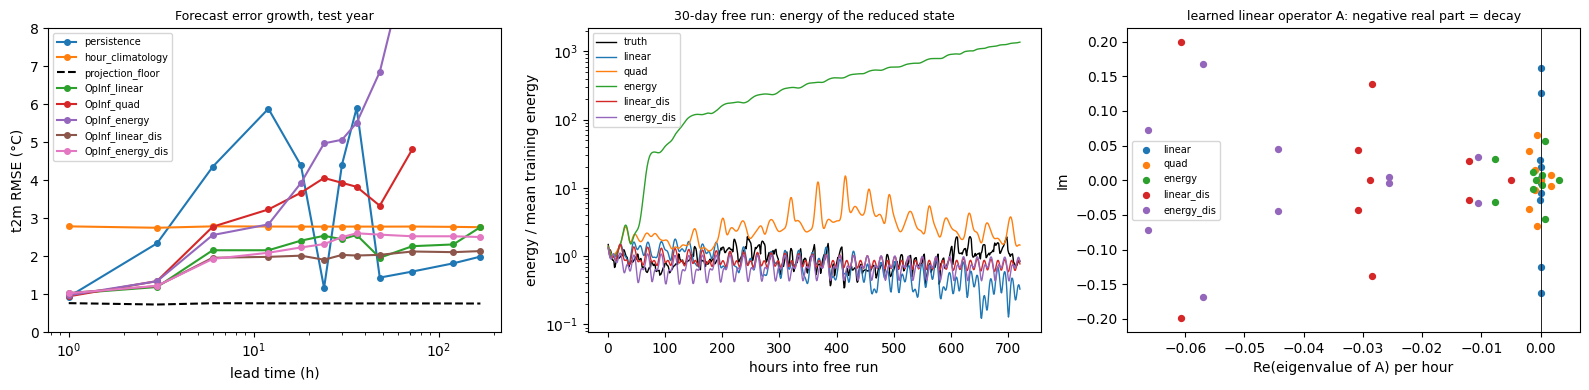

In [27]:
# Cell 13 — summary figure
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for col in [c for c in lt.columns if c != "lead_h"]:
    axs[0].plot(lt.lead_h, lt[col], "k--" if col == "projection_floor" else "o-", ms=4, label=col)
axs[0].set_ylim(0, 8)
axs[0].set_xscale("log"); axs[0].set_xlabel("lead time (h)"); axs[0].set_ylabel("t2m RMSE (°C)"); axs[0].set_title("Forecast error growth, test year", fontsize=9); axs[0].legend(fontsize=7)
hours = np.arange(1, 721); axs[1].plot(hours, np.sum(truth_Z ** 2, 1) / ref_E, "k", lw=1, label="truth")
for k in free: axs[1].plot(hours, np.sum(free[k] ** 2, 1) / ref_E, lw=1, label=k)
axs[1].set_yscale("log"); axs[1].set_xlabel("hours into free run"); axs[1].set_ylabel("energy / mean training energy"); axs[1].set_title("30-day free run: energy of the reduced state", fontsize=9); axs[1].legend(fontsize=7)
for k, m in models.items():
    ev = np.linalg.eigvals(m.A); axs[2].scatter(ev.real, ev.imag, s=18, label=k)
axs[2].axvline(0, color="k", lw=0.6); axs[2].set_xlabel("Re(eigenvalue of A) per hour"); axs[2].set_ylabel("Im"); axs[2].set_title("learned linear operator A: negative real part = decay", fontsize=9); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/E_summary.png", dpi=200); plt.show()

### Cell 14 — save results and models

In [28]:
# Cell 14 — save results and models
for k, m in models.items():
    np.savez_compressed(f"{MOD}/opinf_{k}_r{r}.npz", c=m.c, A=m.A, B=m.B, H=(m.H if m.H is not None else np.zeros((r, r * (r + 1) // 2))))
np.savez_compressed(f"{MOD}/pod_basis_r{r}.npz", V=pod.V.astype(np.float32), mean=pod.mean.astype(np.float32), S=pod.S, mask=MASK, lat=C["lat"], lon=C["lon"], mu=C["mu"], sd=C["sd"])
json.dump({"R_MODES": r, "cells": NC, "state_dim": NSTATE, "splits": SPLITS, "energy_captured": dict(zip(map(str, rs), map(float, etab.energy_captured))),
           "lead_time_t2m": lt.to_dict("records"), "stability": stab.to_dict("records")}, open(f"{OUT}/results_summary.json", "w"), indent=1, default=str)
for sub_ in (TAB, FIG, MOD):
    print(sub_); [print("   ", f) for f in sorted(os.listdir(sub_))]

/content/drive/MyDrive/iitp_project/rom_research/tables
    A_pod_energy.csv
    B_quadratic_manifold.csv
    C_regularisation_choice.csv
    E_by_variable.csv
    E_lead_time_t2m.csv
    E_stability.csv
/content/drive/MyDrive/iitp_project/rom_research/figures
    A_pod_energy.png
    E_summary.png
/content/drive/MyDrive/iitp_project/rom_research/models
    opinf_energy_dis_r10.npz
    opinf_energy_r10.npz
    opinf_linear_dis_r10.npz
    opinf_linear_r10.npz
    opinf_quad_r10.npz
    pod_basis_r10.npz


## How to read and describe the results

* **A (POD)**: report how many modes capture, say, 90 % and 99 % of the energy, and note that the first modes are the daily cycle.
* **B (manifold)**: if the quadratic manifold is clearly better at small mode counts, the data are curved; if not, say a linear subspace is sufficient here.
* **E (forecast)**: compare the operator-inference models against persistence **and** hour-of-day climatology. A reduced model that does not beat climatology at long leads has not learned dynamics, only the daily cycle — this is the honest reading.
* **E (structure ablation)**: compare `linear`, `quad`, `energy`, `linear_dis`, `energy_dis` on the same rows. The questions are: does the energy-preserving `H` fix the divergence of the free `quad` model, and does the dissipative `A` fix the remaining growth (positive `max_Re_eig_A`, energy far above the training level)? Report each answer plainly, including a null result.
* **Data**: the study uses only the hours that exist (see the coverage table of Cell 5), so missing months may bias what the models learn.
* **Limits**: single region, one reanalysis (ERA5-Land, a model product, not observations), forced and dissipative dynamics, structure imposed only through the two constraints above, and no rainfall.

**Natural extensions toward structure-preserving modeling:** a stability-constrained linear operator (`A` forced to have non-positive spectrum), energy-conserving time integration of the learned model, quadratic-manifold operator inference (fit the dynamics in the curved coordinates of Cell 8), and a Hamiltonian test problem (oscillator chain or wave equation) where exact energy conservation is the right physics.